In [1]:
# 錄製檔切分
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import json
import random
from collections import deque
from collections.abc import Mapping
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv

# 訓練模型
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import copy
from tqdm import tqdm

## 2. 讀取dataset： `(N Breath, 3, 256)`

In [2]:
L = 256
CH = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]
CACHE = rf"D:\pva_training\data\training_data\1to4_PC-AC_L{L}"

X = np.load(os.path.join(CACHE, "X.npy"), mmap_mode="r")      # 不加 mmap_mode 就整個讀進記憶體
kb = pd.read_csv(os.path.join(CACHE, "kb.csv"), dtype={"rec": str, "mode": str})
dropped = pd.read_csv(os.path.join(CACHE, "dropped.csv"), dtype={"rec": str})
ids = list(zip(kb["rec"], kb["breath_id"]))
lens = kb["points"].to_numpy()
print("X shape =", X.shape)

X shape = (899454, 3, 256)


## 3. 切訓練集 80% / 驗證集 20%

In [3]:
# seed=0, 隨機打散X排序
rng = np.random.default_rng(0)
perm = rng.permutation(len(X))

# 20% n 當作 val
n_val = int(len(X) * 0.2)

# 前20% val, 後80% train
va_idx, tr_idx = perm[:n_val], perm[n_val:]
print("train", X[tr_idx].shape)
print("val  ", X[va_idx].shape)

train (719564, 3, 256)
val   (179890, 3, 256)


## 4. 標準化（z-score）
不用 min-max 的原因：
1. min-max 容易被極值影響
2. Pressure、Volume 從 0 往上，Flow 有正有負

In [4]:
# Standardization (z-score)： 
mean = X[tr_idx].mean(axis=(0, 2), keepdims=True)        # shape (1, 3, 1)：每個通道一個平均
std  = X[tr_idx].std(axis=(0, 2), keepdims=True) + 1e-6

# x' = (x - mean) / std
Xn = (X - mean) / std

# 轉成torch格式
X_tr = torch.from_numpy(Xn[tr_idx])
X_va = torch.from_numpy(Xn[va_idx])
print("train", X_tr.shape)
print("val  ", X_va.shape)

train torch.Size([719564, 3, 256])
val   torch.Size([179890, 3, 256])


## 5. 建模型

In [5]:
# resampling後，共3*256=768，latent壓縮成16，這樣是48倍壓縮
LATENT = 16 

class ConvAE(nn.Module):
    def __init__(self, in_ch=3, L=L, latent=LATENT):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(in_ch, 16, 7, stride=2, padding=3), nn.ReLU(),   # (N,  3, 256)  -> (N, 16, 128)
            nn.Conv1d(16, 32, 7, stride=2, padding=3), nn.ReLU(),      # (N, 16, 128)  -> (N, 32,  64)
            nn.Conv1d(32, 64, 7, stride=2, padding=3), nn.ReLU(),      # (N, 32,  64)  -> (N, 64,  32)
            nn.Flatten(),                                              # 64*32 = 2048
            nn.Linear(64 * (L // 8), latent),                          # 64*(32)-> latent
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 64 * (L // 8)), nn.ReLU(),                    # 64*(32)-> latent
            nn.Unflatten(1, (64, L // 8)),                                  # 64*32 = 2048
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.ReLU(),  # (N, 64,  32)  -> (N, 32,  64)
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.ReLU(),  # (N, 64,  32)  -> (N, 16, 128)
            nn.ConvTranspose1d(16, in_ch, 4, stride=2, padding=1),          # (N, 16, 128)  -> (N,  3, 256)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)
        
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_tr = X_tr.to(device)
X_va = X_va.to(device)

model = ConvAE().to(device)
print(model(X_tr[:2]).shape)   # 應該要是 [2, 3, 256]，跟輸入一樣
print(device)                                  # cuda 或 cpu

torch.Size([2, 3, 256])
cuda


In [6]:
# 載入模型
SAVE_PATH = "checkpoints/1to4_ae_latent16.pt"
device = "cuda" if torch.cuda.is_available() else "cpu"

ckpt = torch.load(SAVE_PATH, map_location=device)

model = ConvAE().to(device)              # 要先跑過上面 ConvAE 的定義
model.load_state_dict(ckpt["model_state"])
model.eval()                             # eval 模式

print(f"Loaded epoch {ckpt['best_ep']} model, best val = {ckpt['best_val']:.5f}")

# 推論範例
with torch.no_grad():
    recon = model(X_va.to(device))
    err = ((recon - X_va.to(device)) ** 2).mean(dim=tuple(range(1, X_va.ndim)))  # 每口的重建誤差

Loaded epoch 121 model, best val = 0.00316


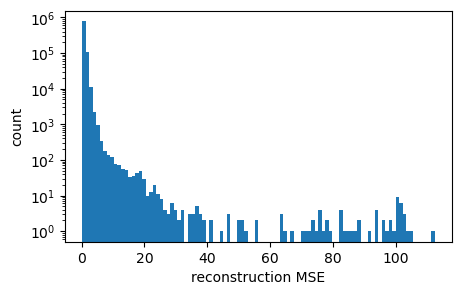

分數最高的 10 口： [['4', '29947'], ['2', '453727'], ['4', '88657'], ['1', '61705'], ['1', '78847'], ['2', '521497'], ['1', '85306'], ['1', '61706'], ['2', '426731'], ['2', '197372']]
分數最低的 5 口： [['2', '601323'], ['4', '90213'], ['4', '140085'], ['1', '58663'], ['1', '129943']]


In [6]:
model = model.cpu()
model.eval()

scores_list, Z_list = [], []
with torch.no_grad():
    for i in range(0, len(Xn), 1024):
        xb = torch.from_numpy(Xn[i:i+1024]).float()
        scores_list.append(((model(xb) - xb) ** 2).mean(dim=(1, 2)))
        Z_list.append(model.encoder(xb))
scores = torch.cat(scores_list).numpy()
Z = torch.cat(Z_list).numpy()  

plt.figure(figsize=(5, 3))
plt.hist(scores, bins=100); plt.yscale("log")
plt.xlabel("reconstruction MSE"); plt.ylabel("count"); plt.show()
ids = np.asarray(ids)

order = np.argsort(scores)[::-1]
print("分數最高的 10 口：", ids[order[:10]].tolist())
print("分數最低的 5 口：", ids[order[-5:]].tolist())

## 9. UMAP + HDBSCAN 分群

In [10]:
# 取出 latent z
import umap
from sklearn.cluster import HDBSCAN                    # sklearn 1.3 以上才有
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

print("Z shape =", Z.shape)                            # (N 口呼吸, LATENT)

# 各維尺度不一樣，先標準化
Zs = StandardScaler().fit_transform(Z).astype(np.float32)

# 抽樣擬合（現在沒用）
# N_FIT = 100_000
# rng9 = np.random.default_rng(42)
# fit_idx = np.sort(rng9.choice(len(Zs), size=min(N_FIT, len(Zs)), replace=False))
# Z_fit = Zs[fit_idx]
# print("擬合用筆數 =", len(fit_idx))


# 用全部資料擬合
fit_idx = np.arange(len(Zs))
Z_fit = Zs
print("擬合用筆數 =", len(fit_idx))

Z shape = (899454, 16)
擬合用筆數 = 899454


In [ ]:
# # # UMAP
# N_COMP = min(5, Z.shape[1])

# # 分群
# reducer = umap.UMAP(n_neighbors=10, min_dist=0.0, n_components=5,
#                     low_memory=False, verbose=True)
# E_fit = reducer.fit_transform(Z_fit)                   

# # 畫圖
# reducer2d = umap.UMAP(n_neighbors=10, min_dist=0.1, n_components=2,
#                       low_memory=False, verbose=True)
# E2_fit = reducer2d.fit_transform(Z_fit)                

# print("分群空間", E_fit.shape, "  畫圖空間", E2_fit.shape)

In [27]:
# np.savez("1to4_umap_cache.npz", E_fit=E_fit, E2_fit=E2_fit, fit_idx=fit_idx)

In [7]:
# UMAP，有快取就直接讀
import os
N_COMP = min(5, Z.shape[1])

CACHE = r"D:\pva_training\cache\1to4_umap_cache.npz"

if os.path.exists(CACHE):
    d = np.load(CACHE)
    E_fit, E2_fit = d["E_fit"], d["E2_fit"]
    print("已從快取載入", CACHE)
else:
    # 分群用
    reducer = umap.UMAP(n_neighbors=10, min_dist=0.0, n_components=N_COMP,
                        random_state=42, low_memory=True, verbose=True)
    E_fit = reducer.fit_transform(Z_fit)

    # 畫圖用
    reducer2d = umap.UMAP(n_neighbors=10, min_dist=0.1, n_components=2,
                          random_state=42, low_memory=True, verbose=True)
    E2_fit = reducer2d.fit_transform(Z_fit)

    np.savez(CACHE, E_fit=E_fit, E2_fit=E2_fit, fit_idx=fit_idx)
    print("已存檔", CACHE)

print("分群空間", E_fit.shape, "  畫圖空間", E2_fit.shape)

已從快取載入 D:\pva_training\cache\1to4_umap_cache.npz
分群空間 (899454, 5)   畫圖空間 (899454, 2)


In [8]:
# HDBSCAN，有快取就直接讀
import os
from fast_hdbscan import HDBSCAN as FastHDBSCAN

MIN_CLUSTER_SIZE = 180
MIN_SAMPLES      = None

# 檔名有參數和筆數，改參數或換資料會重算
LAB_CACHE = os.path.join(
    r"D:\pva_training\cache",
    f"hdbscan_labels_mcs{MIN_CLUSTER_SIZE}_ms{MIN_SAMPLES}_n{len(E_fit)}.npy"
)

if os.path.exists(LAB_CACHE):
    lab_fit = np.load(LAB_CACHE)
    print("已從快取載入", LAB_CACHE)
else:
    hdb = FastHDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
    lab_fit = hdb.fit_predict(E_fit)               # 群號，-1 = 雜訊
    np.save(LAB_CACHE, lab_fit)
    print("已存檔", LAB_CACHE)

n_clu = lab_fit.max() + 1
print(f"群數 = {n_clu}，雜訊 = {(lab_fit < 0).sum()} 口（{(lab_fit < 0).mean():.2%}）")
print(pd.Series(lab_fit, name="口數").value_counts().sort_index().to_string())

已從快取載入 D:\pva_training\cache\hdbscan_labels_mcs180_msNone_n899454.npy
群數 = 62，雜訊 = 29958 口（3.33%）
口數
-1      29958
 0        210
 1        930
 2       5075
 3        208
 4       3999
 5       1016
 6       4980
 7     101283
 8        560
 9       1210
 10       669
 11       284
 12    447246
 13      1150
 14       295
 15       602
 16      1335
 17      2594
 18       283
 19     12621
 20       367
 21    200025
 22       235
 23      3523
 24       288
 25       247
 26       316
 27      1050
 28       467
 29       555
 30       856
 31       345
 32       375
 33       564
 34      1316
 35      1375
 36       991
 37      6459
 38       600
 39       547
 40       615
 41       474
 42      1054
 43      1169
 44       458
 45       286
 46      5108
 47      6965
 48       281
 49     28669
 50       511
 51       324
 52       432
 53       824
 54       466
 55       249
 56       659
 57      1091
 58      1397
 59      1059
 60      1156
 61      9198


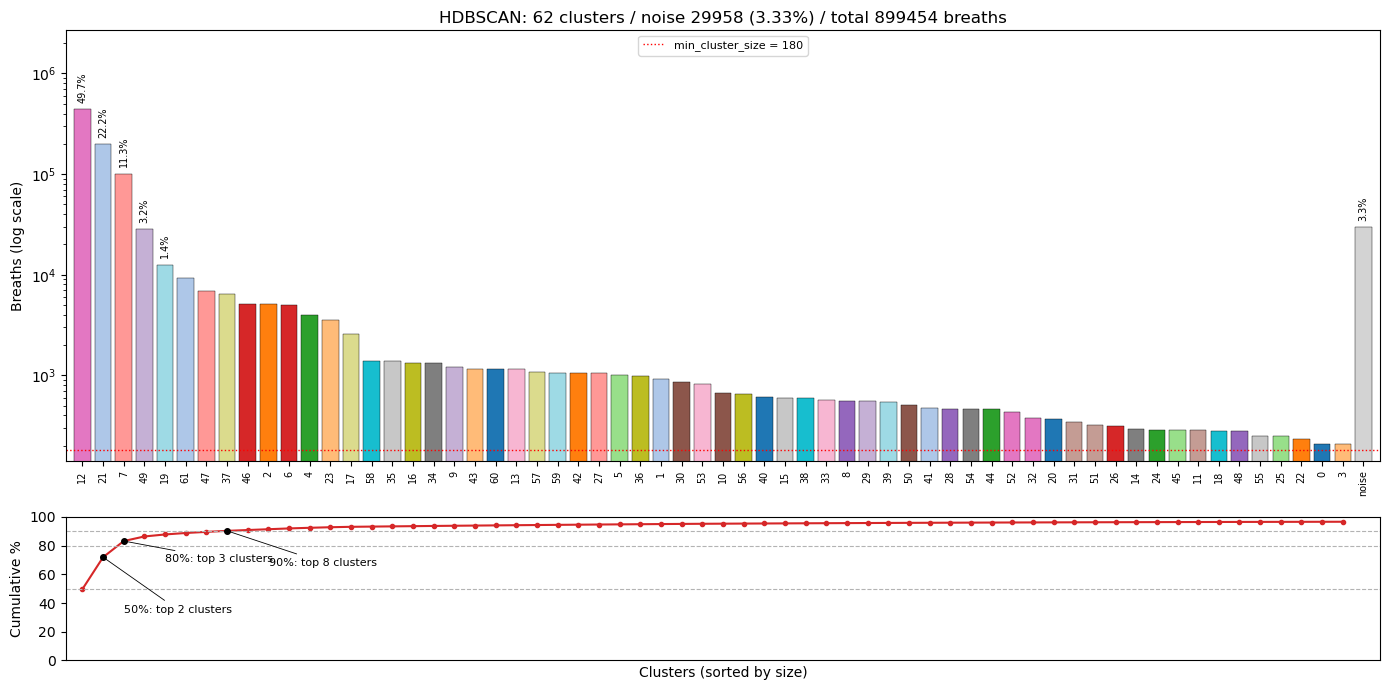

In [9]:
# 各群口數
cnt = pd.Series(lab_fit).value_counts()
clu = cnt.drop(-1, errors="ignore").sort_values(ascending=False)    # 由大到小排
n_noise = int(cnt.get(-1, 0))
total = len(lab_fit)

fig, ax = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={"height_ratios": [3, 1]})

# 上圖：各群口數，用 log 軸不然小群看不到；顏色跟 UMAP 圖一樣
x = np.arange(len(clu))
ax[0].bar(x, clu.values, color=[plt.cm.tab20(c % 20) for c in clu.index], edgecolor="k", lw=0.3)
ax[0].bar(len(clu), n_noise, color="lightgray", edgecolor="k", lw=0.3)          # 雜訊放最右邊
ax[0].set_yscale("log")
ax[0].set_xticks(list(x) + [len(clu)])
ax[0].set_xticklabels([str(c) for c in clu.index] + ["noise"], rotation=90, fontsize=7)
ax[0].set_xlim(-0.8, len(clu) + 0.8)
ax[0].set_ylabel("Breaths (log scale)")
ax[0].axhline(MIN_CLUSTER_SIZE, color="r", ls=":", lw=1, label=f"min_cluster_size = {MIN_CLUSTER_SIZE}")
for i, c in enumerate(clu.index[:5]):                                           # 前 5 大群標比例
    ax[0].text(i, clu[c] * 1.15, f"{clu[c] / total:.1%}", ha="center", va="bottom", fontsize=7, rotation=90)
ax[0].text(len(clu), n_noise * 1.15, f"{n_noise / total:.1%}", ha="center", va="bottom", fontsize=7, rotation=90)
ax[0].set_ylim(top=clu.max() * 6)                                              # 留空間給比例的字
ax[0].legend(loc="upper center", fontsize=8)
ax[0].set_title(f"HDBSCAN: {len(clu)} clusters / noise {n_noise} ({n_noise / total:.2%}) / "
                f"total {total} breaths")

# 下圖：累積比例
cum = clu.cumsum().to_numpy() / total
ax[1].plot(x, cum * 100, "o-", ms=3, color="C3")
for p, off in ((50, (15, -40)), (80, (30, -15)), (90, (30, -25))):
    k = int(np.searchsorted(cum, p / 100))
    if k < len(clu):
        ax[1].axhline(p, color="0.7", ls="--", lw=0.8)
        ax[1].plot(k, cum[k] * 100, "ko", ms=4)
        ax[1].annotate(f"{p}%: top {k + 1} clusters", (k, cum[k] * 100), xytext=off,
                       textcoords="offset points", fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.6))
ax[1].set_xlim(ax[0].get_xlim()); ax[1].set_xticks([])
ax[1].set_ylim(0, 100); ax[1].set_ylabel("Cumulative %")
ax[1].set_xlabel("Clusters (sorted by size)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR if "FIG_DIR" in globals() else ".", "cluster_sizes.png"), dpi=120)
plt.show()

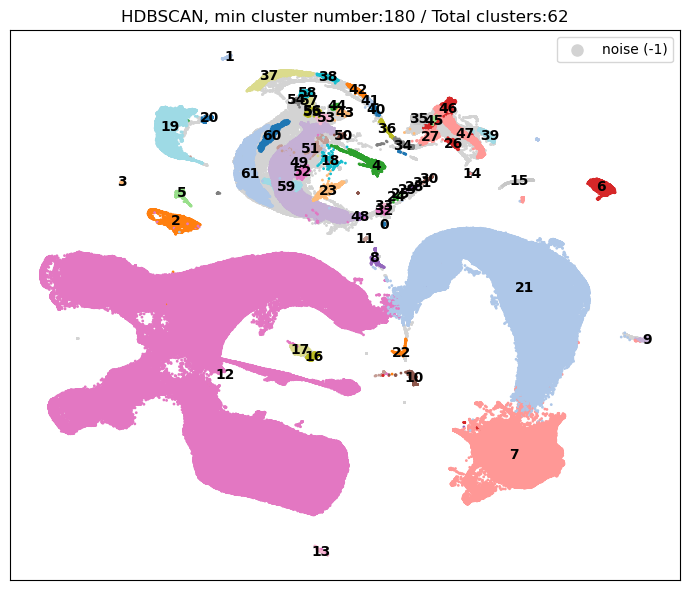

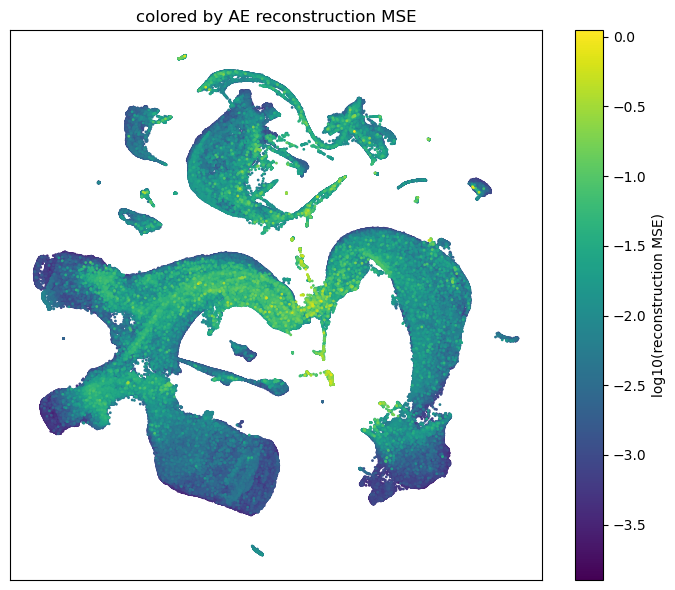

In [14]:
# 2D UMAP，依群上色
noise = lab_fit < 0
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(*E2_fit[noise].T, s=1, c="lightgray", label="noise (-1)", rasterized=True)
ax.scatter(*E2_fit[~noise].T, s=1, c=lab_fit[~noise] % 20, cmap="tab20", vmin=0, vmax=19, rasterized=True)
for c in range(n_clu):                                 # 群號標在每群中心
    m = np.median(E2_fit[lab_fit == c], axis=0)
    ax.text(*m, str(c), fontsize=10, weight="bold", ha="center", va="center")
ax.set_title(f"HDBSCAN, min cluster number:{MIN_CLUSTER_SIZE} / Total clusters:{n_clu}")
ax.legend(markerscale=8, loc="best")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()


# 2D UMAP，依重建 MSE 上色
s_fit = scores[fit_idx]
o = np.argsort(s_fit)                                  # MSE 高的畫在上面
fig, ax = plt.subplots(figsize=(7, 6))

sc = ax.scatter(*E2_fit[o].T, s=1, c=np.log10(s_fit[o]), cmap="viridis", rasterized=True)
plt.colorbar(sc, ax=ax, label="log10(reconstruction MSE)")
ax.set_title("colored by AE reconstruction MSE")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

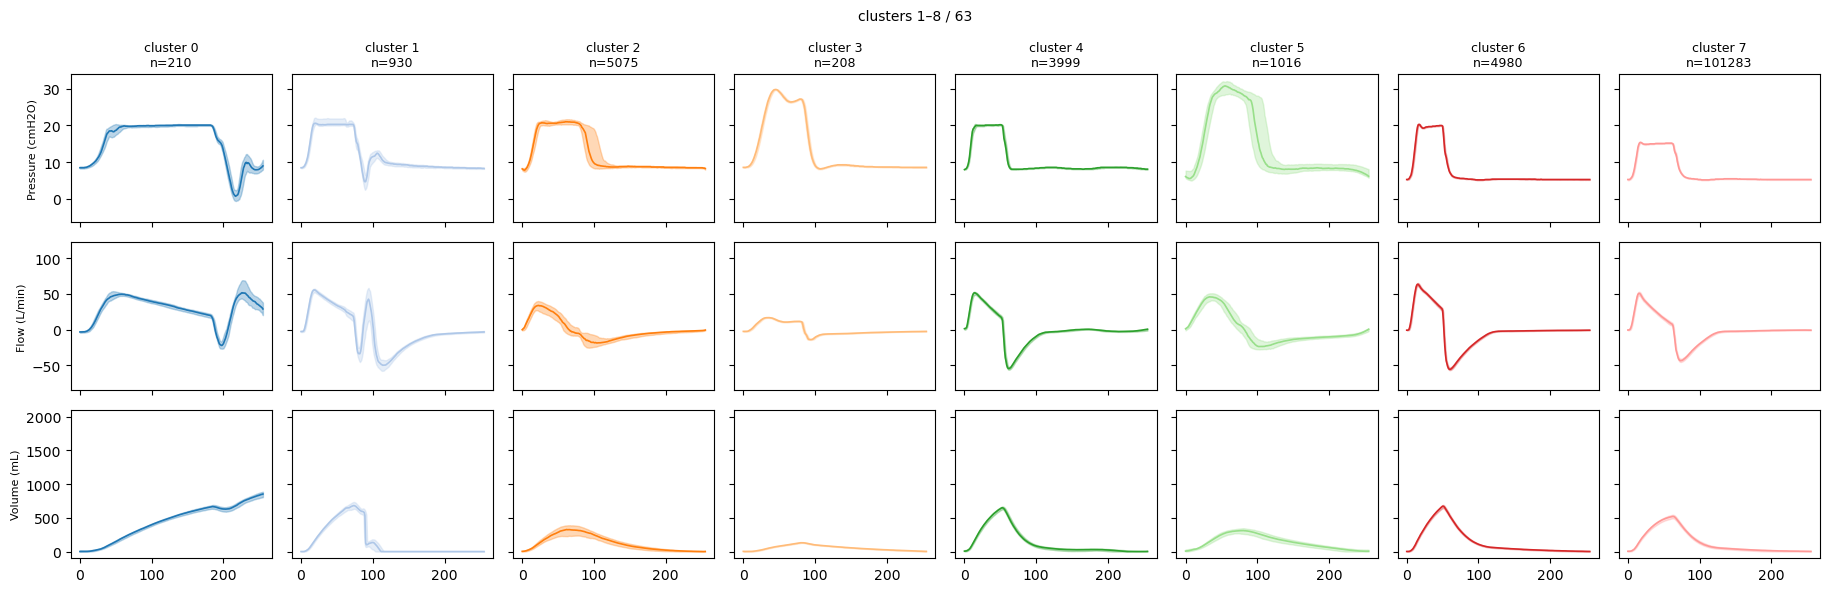

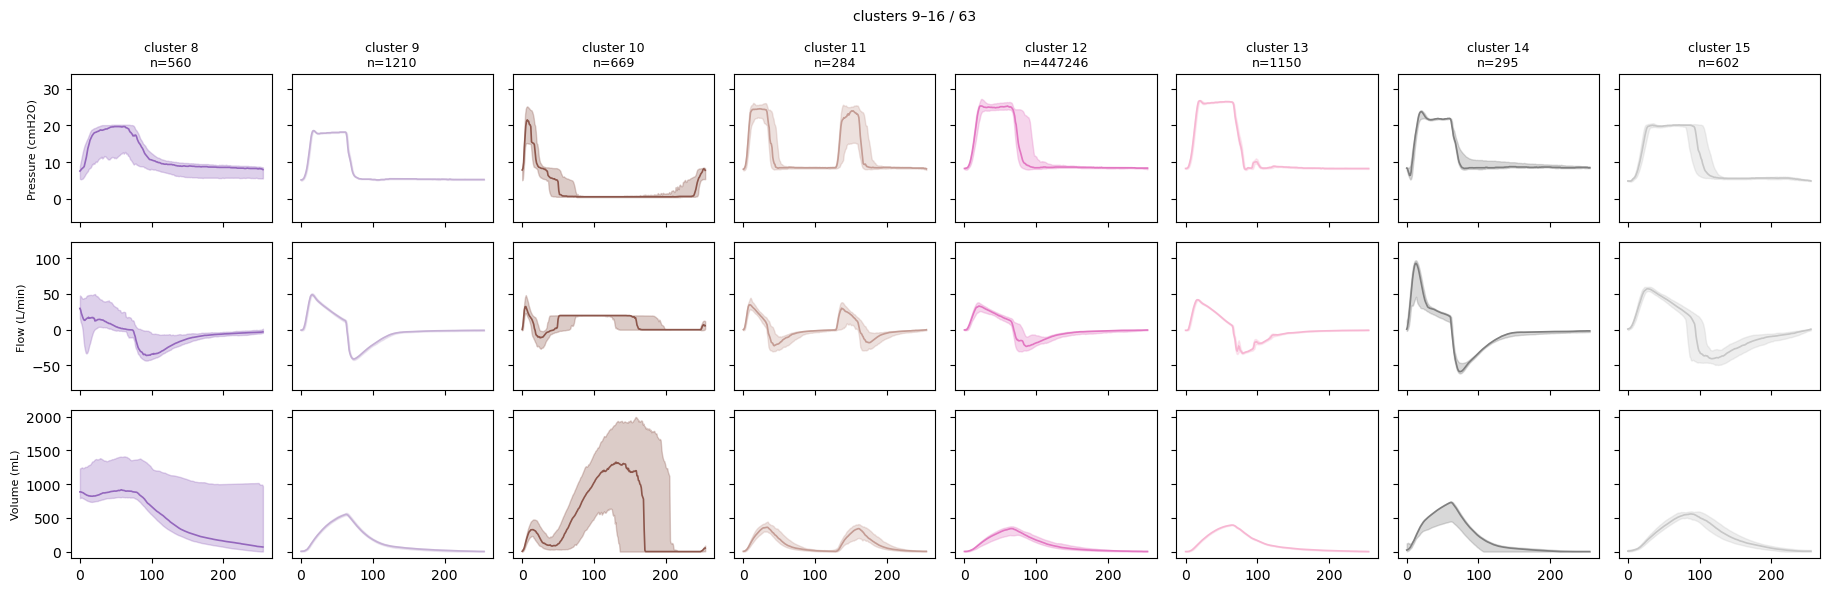

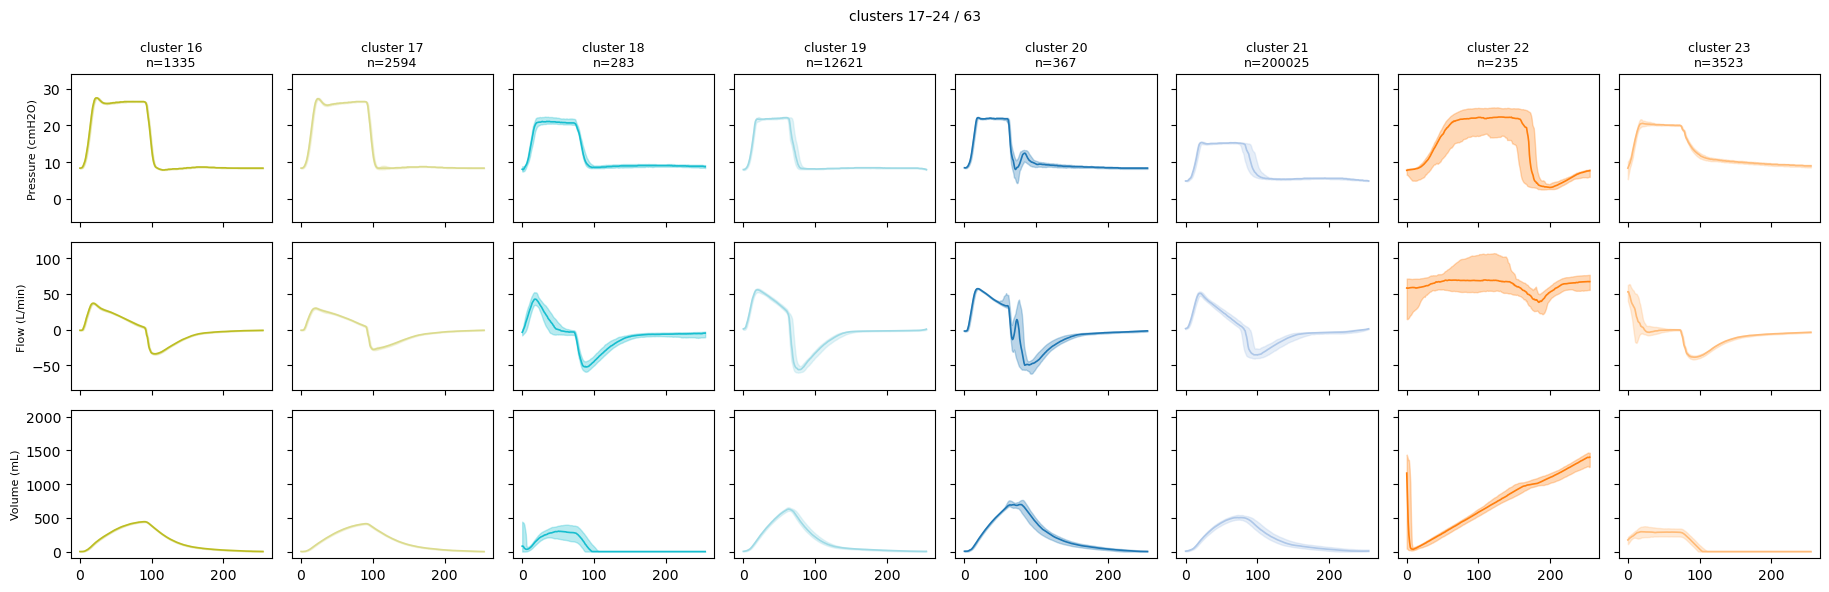

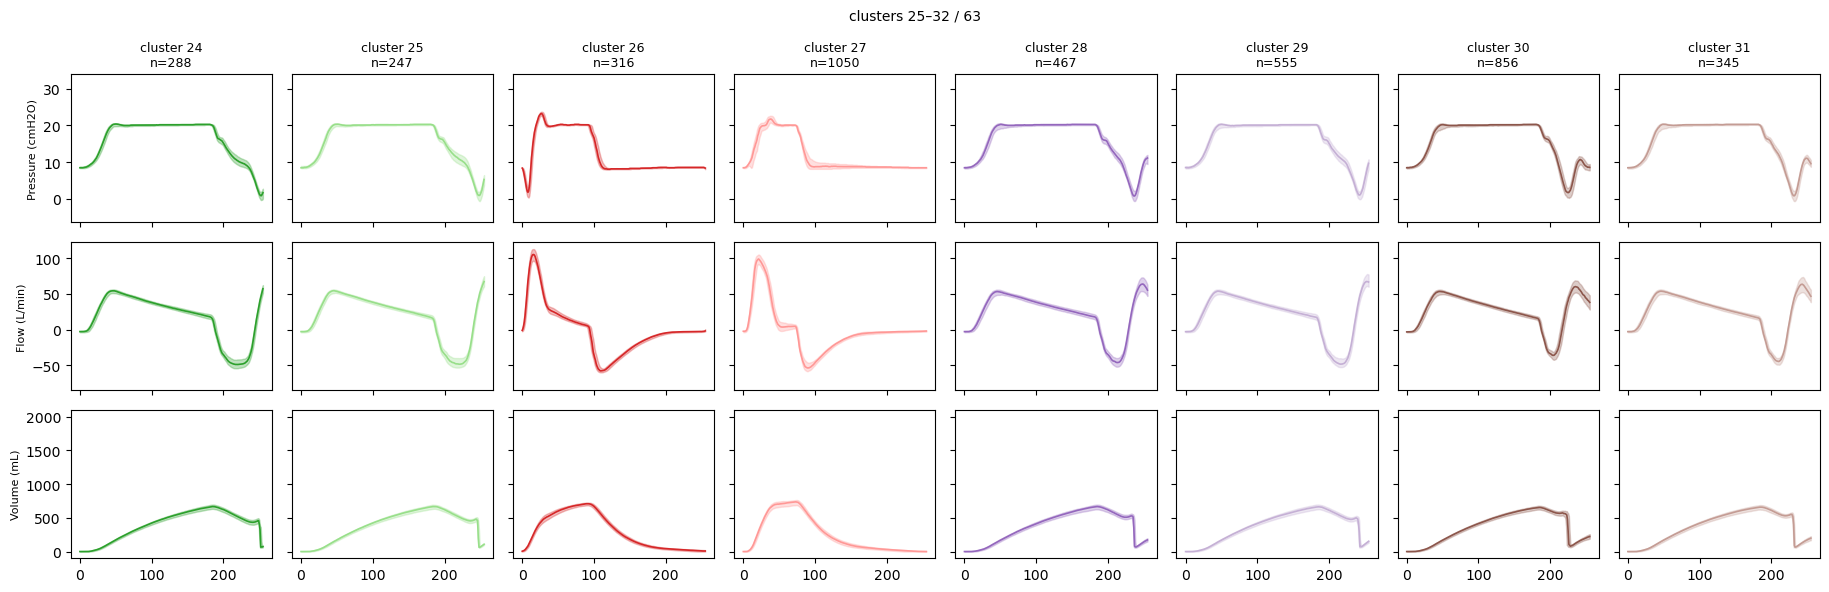

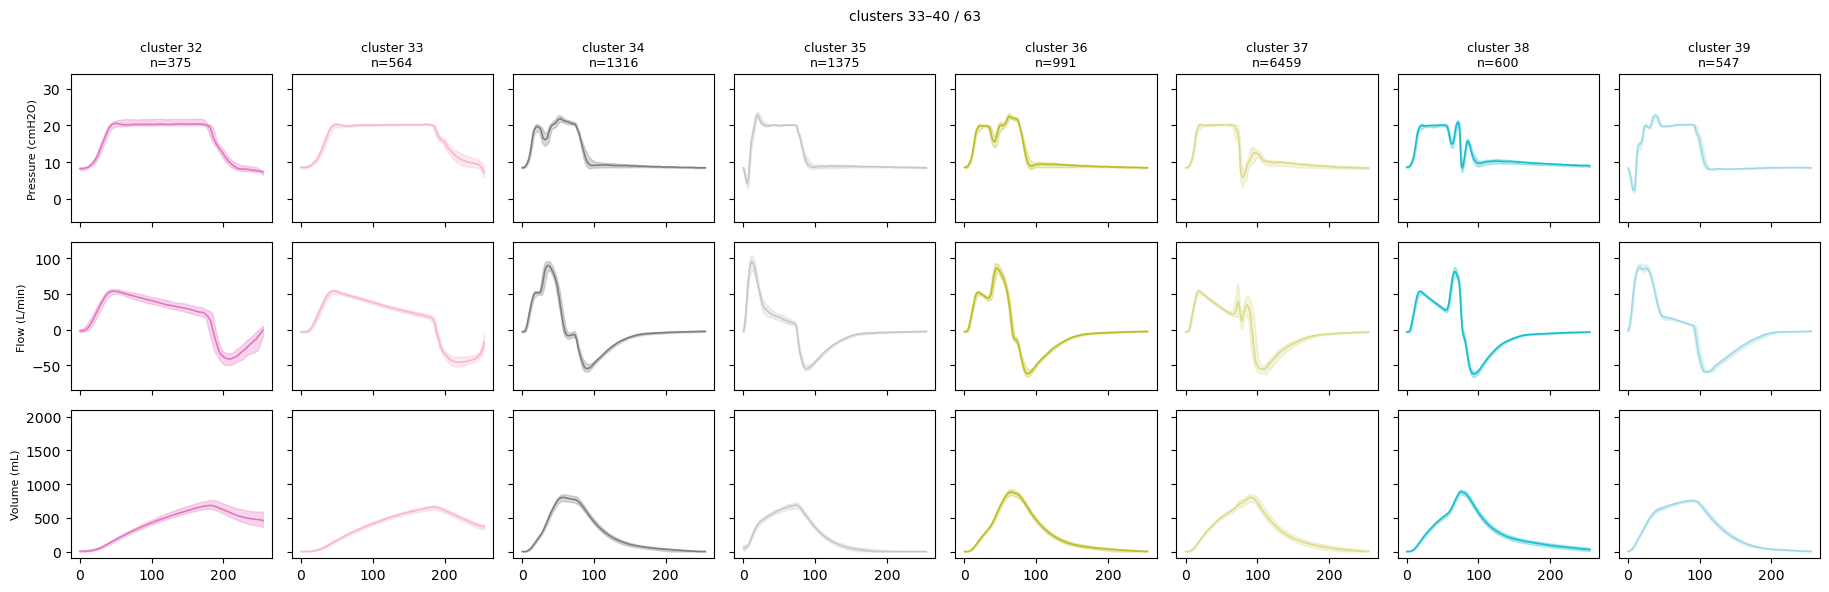

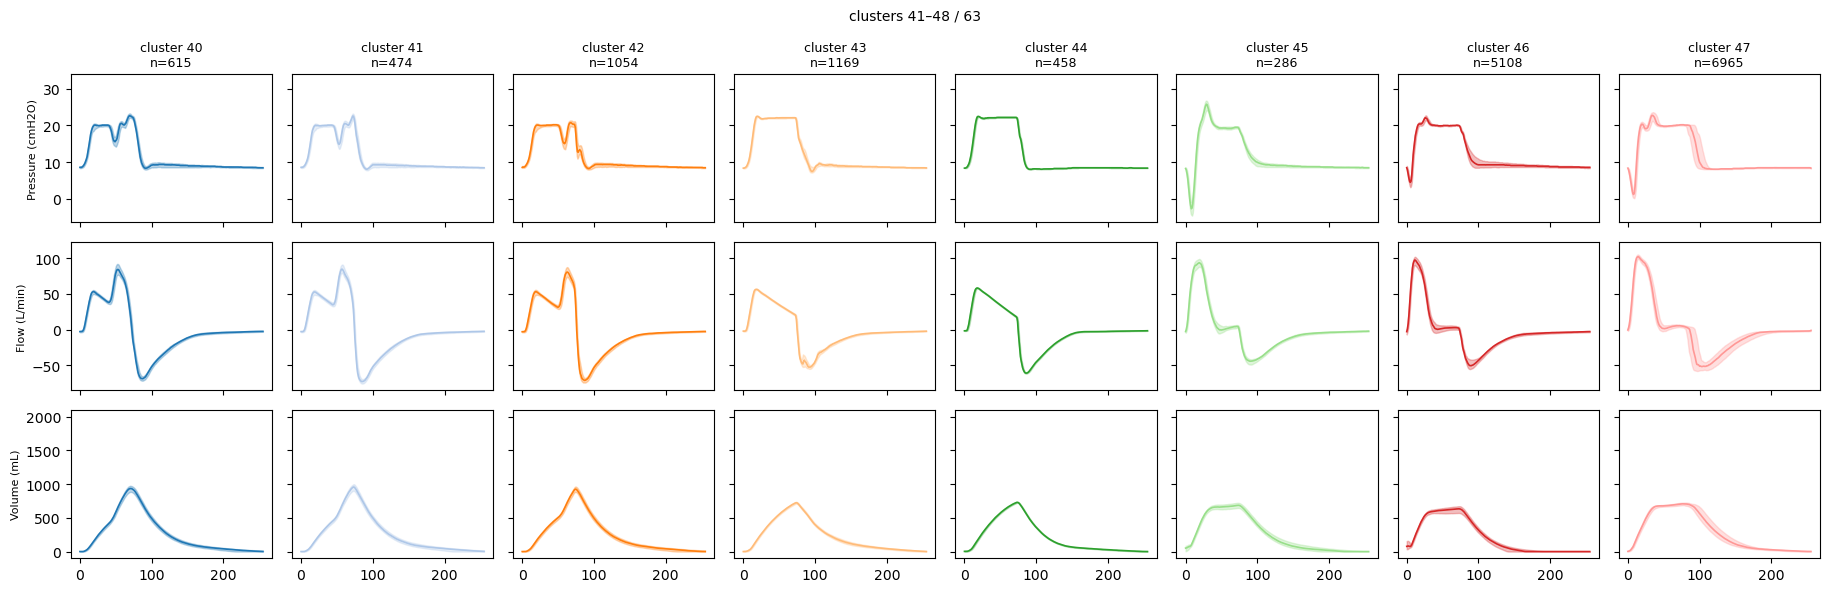

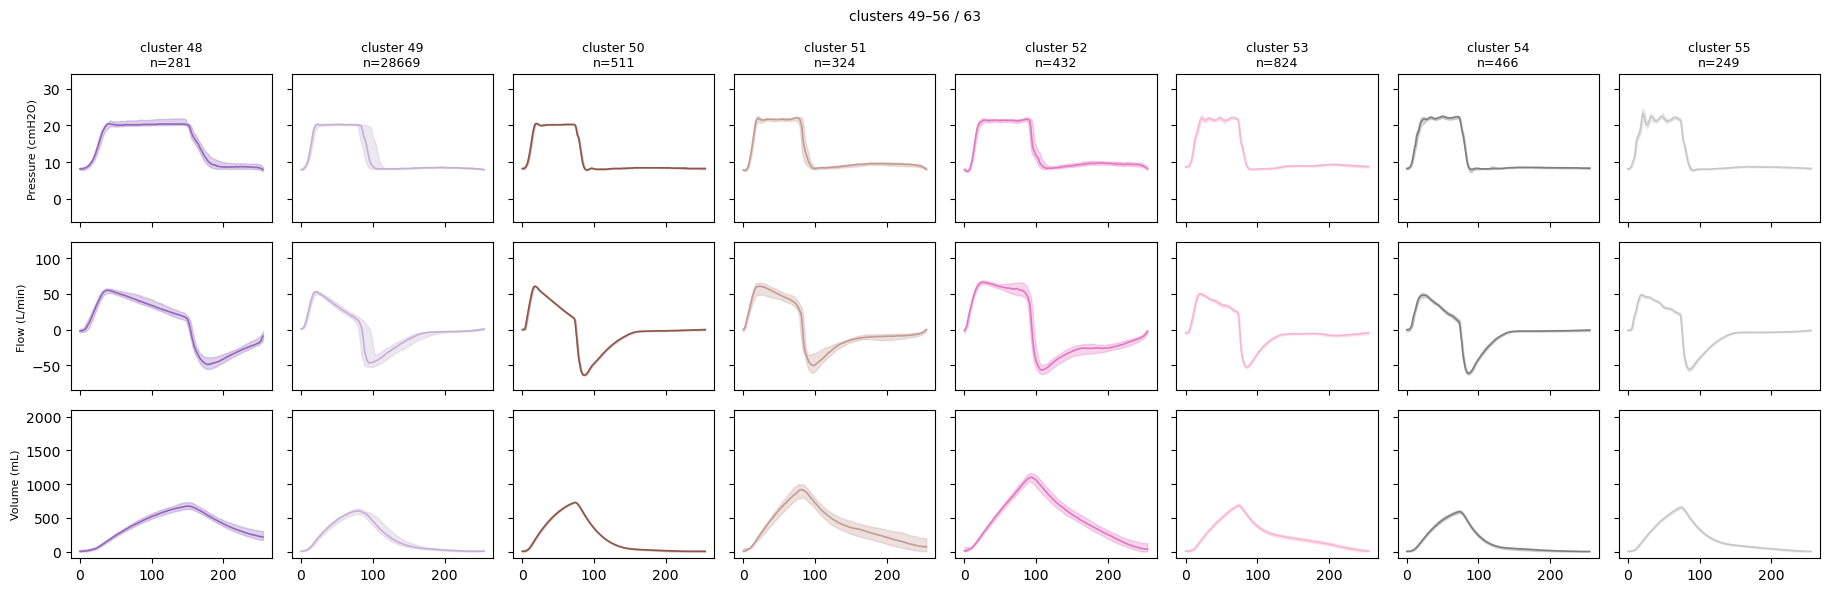

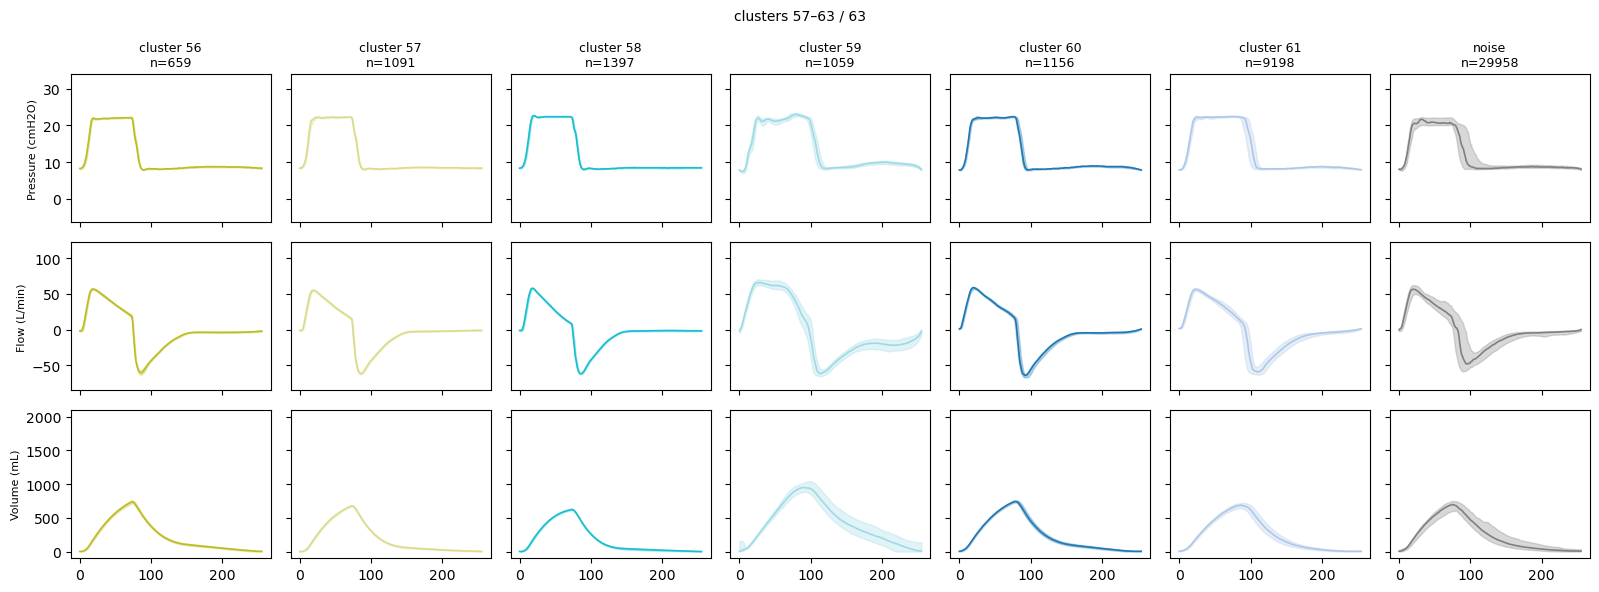

In [17]:
# 每群的代表波形，實線是中位數，色帶是 25～75%
PER_FIG = 8                                            # 每張圖放幾群
N_PICK  = 300                                          # 每群抽幾口來算中位數

# 資料夾名稱帶 latent 和 min_cluster_size；換資料要自己改名，不然會蓋掉
FIG_DIR = f"Latent{Z.shape[1]}_ClusterSize{MIN_CLUSTER_SIZE}"
os.makedirs(FIG_DIR, exist_ok=True)

show = list(range(n_clu)) + [-1]                       # 全部群（依群號）+ 雜訊

# 先算每群分位數，順便抓 y 範圍讓每張圖 y 軸一樣
stats, ylim = {}, np.array([[np.inf, -np.inf]] * 3)
rng9 = np.random.default_rng() 
for c in show:
    members = fit_idx[lab_fit == c]
    if len(members) == 0: continue
    pick = np.sort(rng9.choice(members, size=min(N_PICK, len(members)), replace=False))
    w = np.asarray(X[pick])                            # (n, 3, L)
    q = np.percentile(w, [25, 50, 75], axis=0)         # (3 分位, 3 通道, L)
    stats[c] = (q, len(members))
    ylim[:, 0] = np.minimum(ylim[:, 0], q[0].min(axis=1))
    ylim[:, 1] = np.maximum(ylim[:, 1], q[2].max(axis=1))
pad = (ylim[:, 1] - ylim[:, 0]) * 0.05

groups = [c for c in show if c in stats]
for p in range(0, len(groups), PER_FIG):
    page = groups[p:p + PER_FIG]
    fig, ax = plt.subplots(3, len(page), figsize=(2.3 * len(page), 6),
                           sharex=True, squeeze=False)
    for j, c in enumerate(page):
        q, n = stats[c]
        col = "0.5" if c < 0 else plt.cm.tab20(c % 20)
        for i in range(3):
            ax[i, j].fill_between(range(L), q[0, i], q[2, i], color=col, alpha=.3)
            ax[i, j].plot(q[1, i], color=col, lw=1.2)
            ax[i, j].set_ylim(ylim[i, 0] - pad[i], ylim[i, 1] + pad[i])
            if j == 0: ax[i, j].set_ylabel(CH[i], fontsize=8)
            else:      ax[i, j].set_yticklabels([])
        ax[0, j].set_title(("noise" if c < 0 else f"cluster {c}") + f"\nn={n}", fontsize=9)
    fig.suptitle(f"clusters {p + 1}–{p + len(page)} / {len(groups)}", fontsize=10)
    plt.tight_layout()
    
    fig.savefig(os.path.join(FIG_DIR, f"page{p // PER_FIG + 1:02d}.png"), dpi=150)
    plt.show()

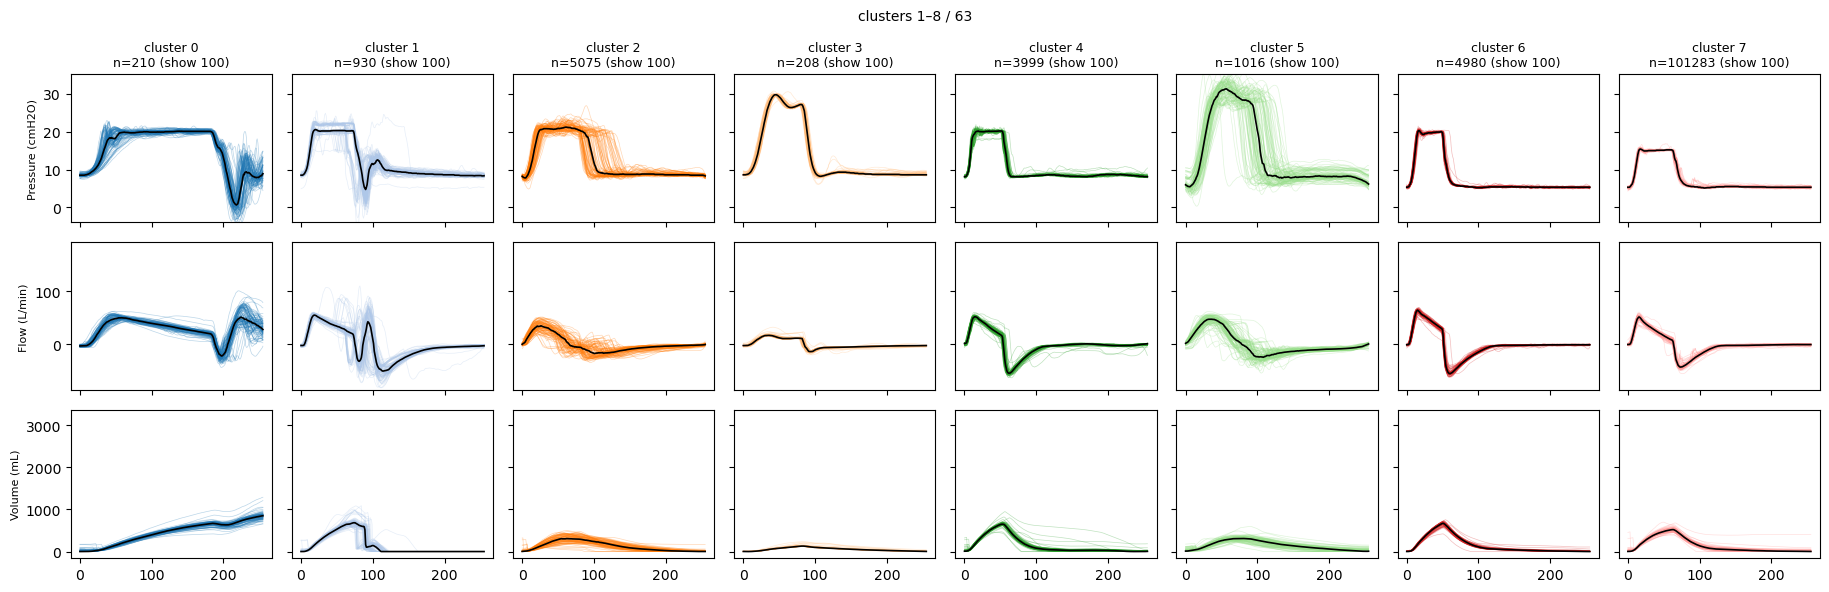

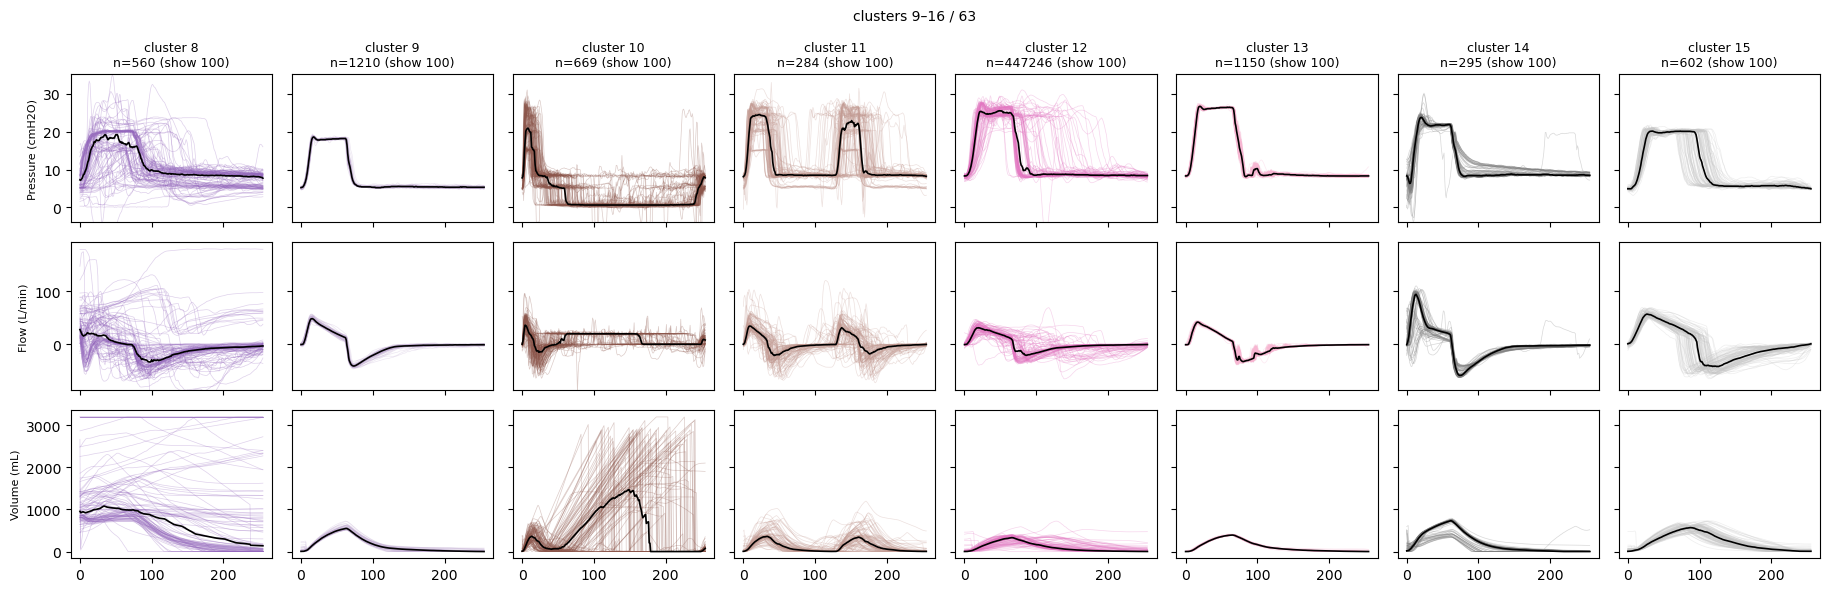

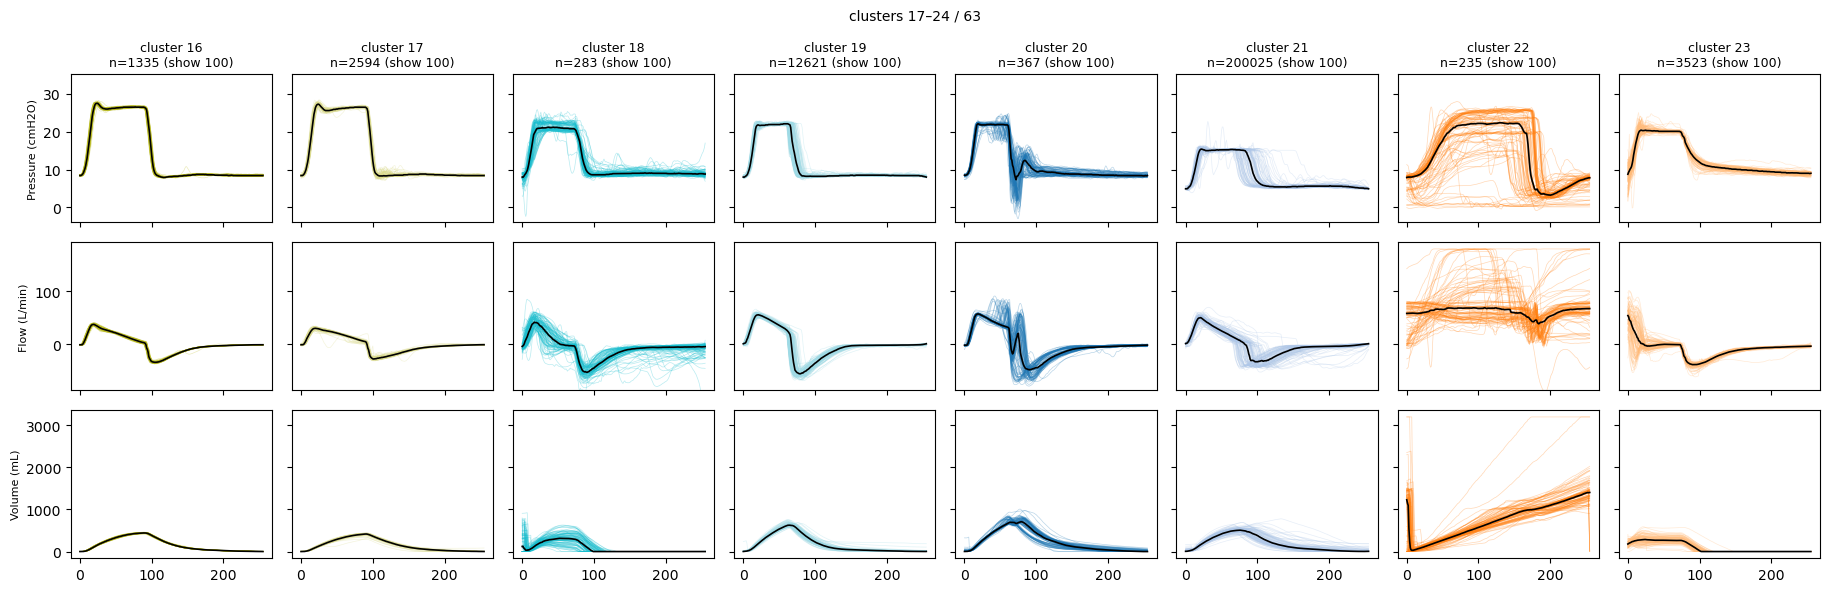

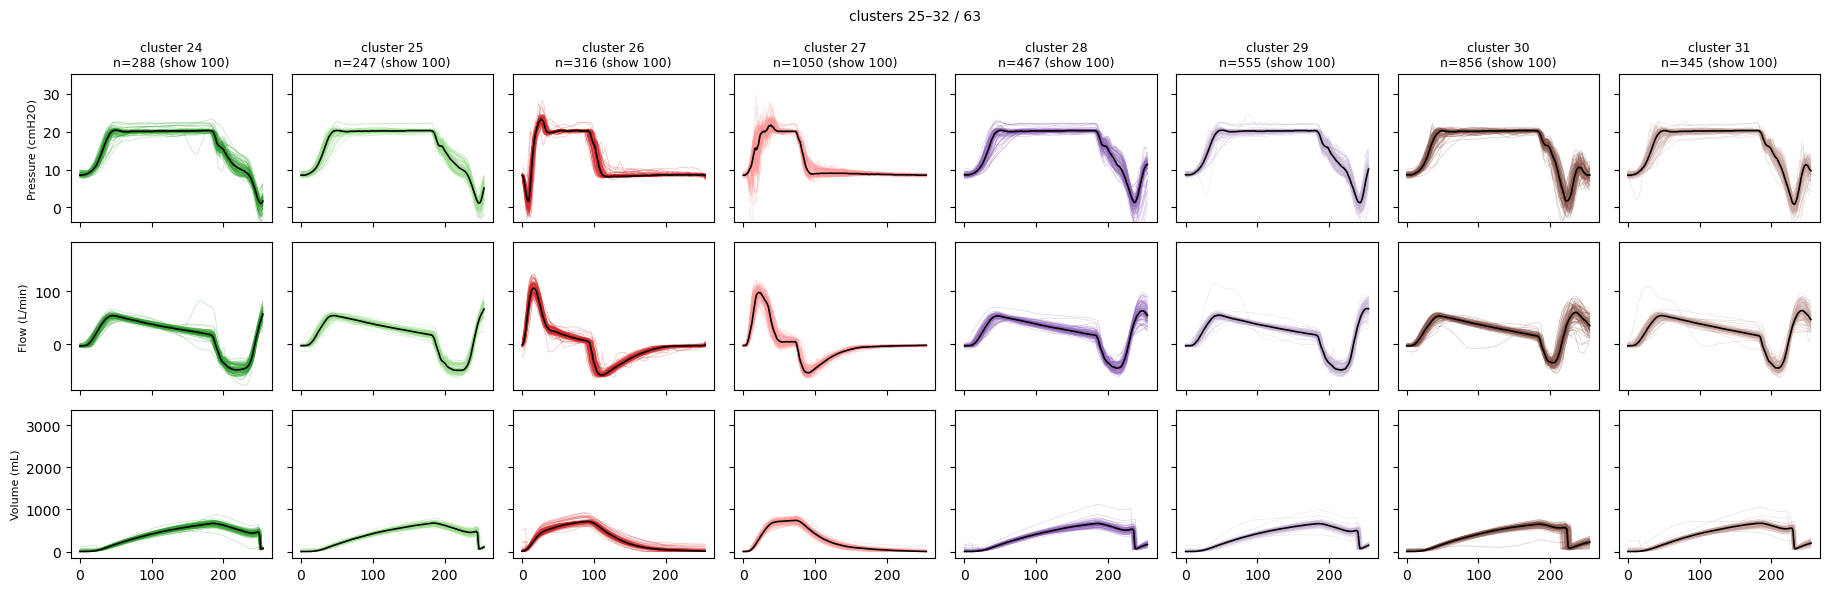

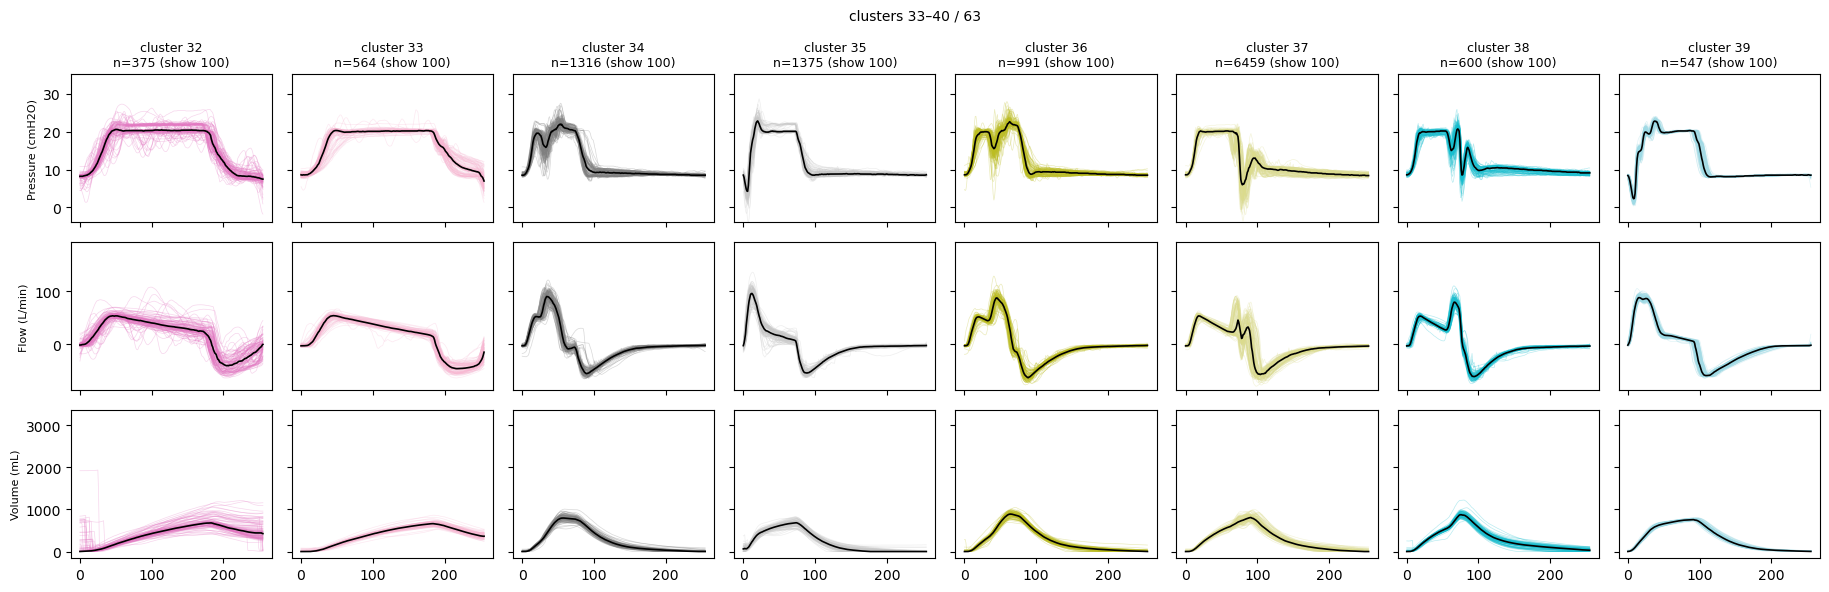

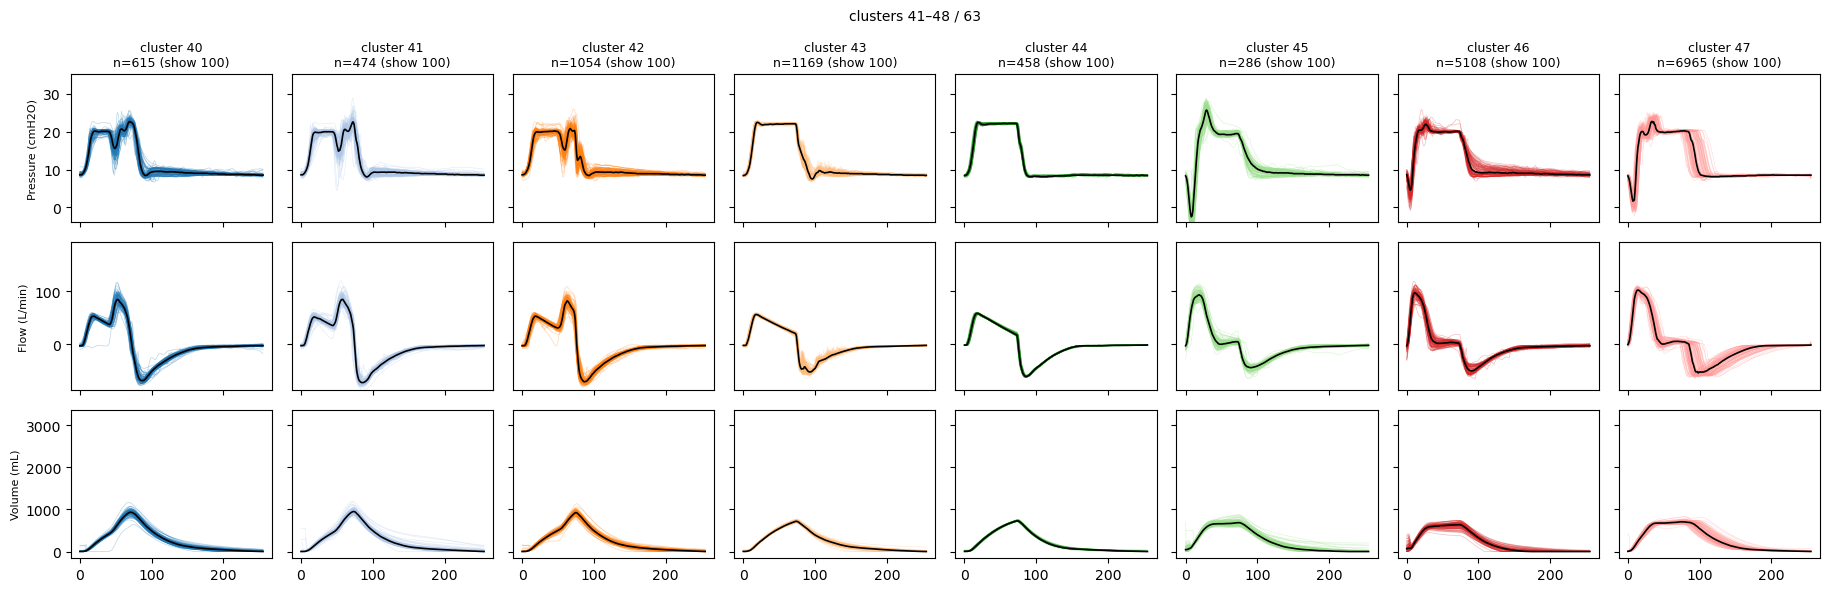

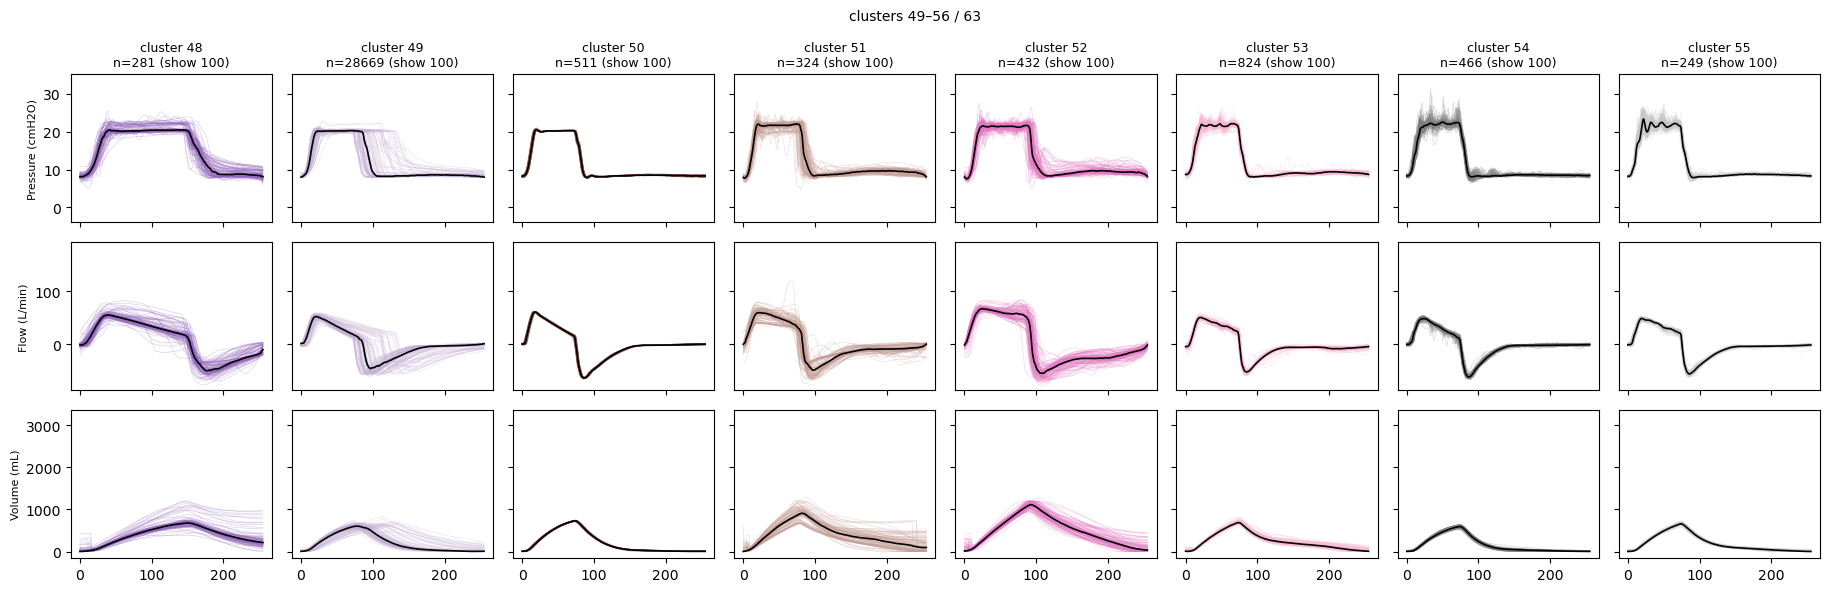

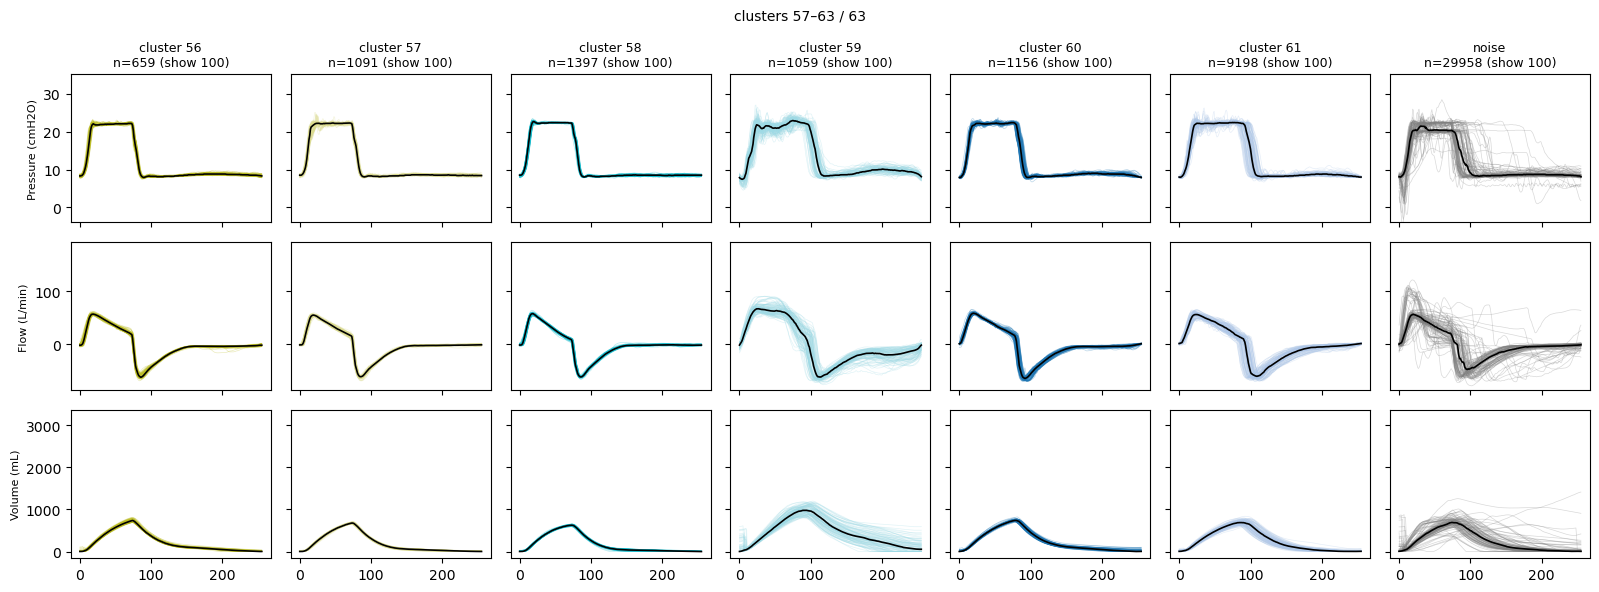

In [18]:
# 每群抽 N_PICK 口畫原始波形，黑線是中位數
PER_FIG = 8                                            # 每張圖放幾群
N_PICK  = 100                                           # 每群抽幾口來畫

# 資料夾名稱帶 latent 和 min_cluster_size；換資料要自己改名，不然會蓋掉
FIG_DIR = f"Latent{Z.shape[1]}_ClusterSize{MIN_CLUSTER_SIZE}_Sample{N_PICK}"
os.makedirs(FIG_DIR, exist_ok=True)

show = list(range(n_clu)) + [-1]                       # 全部群（依群號）+ 雜訊

# 先抽好波形，y 範圍用 1～99 百分位，不然會被極端值壓扁
samples, ylim = {}, np.array([[np.inf, -np.inf]] * 3)
rng9 = np.random.default_rng()                         # 要固定抽樣就改 default_rng(0)
for c in show:
    members = fit_idx[lab_fit == c]
    if len(members) == 0: continue
    pick = np.sort(rng9.choice(members, size=min(N_PICK, len(members)), replace=False))
    w = np.asarray(X[pick])                            # (n, 3, L)
    samples[c] = (w, len(members))
    ylim[:, 0] = np.minimum(ylim[:, 0], np.percentile(w, 1,  axis=(0, 2)))
    ylim[:, 1] = np.maximum(ylim[:, 1], np.percentile(w, 99, axis=(0, 2)))
pad = (ylim[:, 1] - ylim[:, 0]) * 0.05

groups = [c for c in show if c in samples]
for p in range(0, len(groups), PER_FIG):
    page = groups[p:p + PER_FIG]
    fig, ax = plt.subplots(3, len(page), figsize=(2.3 * len(page), 6),
                           sharex=True, squeeze=False)
    for j, c in enumerate(page):
        w, n = samples[c]
        col = "0.5" if c < 0 else plt.cm.tab20(c % 20)
        for i in range(3):
            ax[i, j].plot(w[:, i].T, color=col, lw=0.5, alpha=0.3)          # 一次畫完
            ax[i, j].plot(np.median(w[:, i], axis=0), color="k", lw=1.2)   # 中位數
            ax[i, j].set_ylim(ylim[i, 0] - pad[i], ylim[i, 1] + pad[i])
            if j == 0: ax[i, j].set_ylabel(CH[i], fontsize=8)
            else:      ax[i, j].set_yticklabels([])
        ax[0, j].set_title(("noise" if c < 0 else f"cluster {c}")
                           + f"\nn={n} (show {len(w)})", fontsize=9)
    fig.suptitle(f"clusters {p + 1}–{p + len(page)} / {len(groups)}", fontsize=10)
    plt.tight_layout()

    fig.savefig(os.path.join(FIG_DIR, f"page{p // PER_FIG + 1:02d}_sample{N_PICK}.png"), dpi=150)
    plt.show()

In [10]:
# 每群的病人分布
patient_id = ids[:, 0]          # kb.csv 的 rec
assert len(lab_fit) == len(patient_id)

df = pd.DataFrame({"cluster": lab_fit, "patient": patient_id})
global_share = df["patient"].value_counts(normalize=True)
print("全部資料的病人比例：")
print(global_share.map("{:.2%}".format).to_string())

rows = []
for c, g in df[df["cluster"] >= 0].groupby("cluster"):
    p = g["patient"].value_counts(normalize=True)
    top_patient = p.index[0]
    rows.append({
        "cluster": c,
        "n": len(g),
        "n_patients": p.size,
        "top_patient": top_patient,
        "top_share": p.iloc[0],
        "global_share": global_share[top_patient],
        "lift": p.iloc[0] / global_share[top_patient],
        "effective_patients": np.exp(-(p * np.log(p)).sum()),
    })

summary = pd.DataFrame(rows).sort_values("n", ascending=False)
summary.to_csv("cluster_patient_summary.csv", index=False)

n_specific = (summary["top_share"] > 0.8).sum()
print(f"\ntop_share > 80% 的群：{n_specific} / {len(summary)}")
print(summary["top_patient"].value_counts().to_string())

print("\n雜訊的病人比例：")
print(df.loc[df["cluster"] < 0, "patient"]
        .value_counts(normalize=True).map("{:.2%}".format).to_string())

print("\n最大的 20 群：")
print(summary.head(20).round(3).to_string(index=False))

全部資料的病人比例：
patient
2    51.01%
4    34.06%
1    14.58%
3     0.34%

top_share > 80% 的群：58 / 62
top_patient
1    47
2    10
4     4
3     1

雜訊的病人比例：
patient
1    97.39%
2     1.26%
4     0.76%
3     0.59%

最大的 20 群：
 cluster      n  n_patients top_patient  top_share  global_share    lift  effective_patients
      12 447246           4           2      0.998         0.510   1.956               1.017
      21 200025           4           4      0.991         0.341   2.910               1.054
       7 101283           4           4      0.999         0.341   2.934               1.007
      49  28669           3           1      1.000         0.146   6.856               1.004
      19  12621           2           1      1.000         0.146   6.858               1.002
      61   9198           2           1      1.000         0.146   6.857               1.002
      47   6965           1           1      1.000         0.146   6.859               1.000
      37   6459           3           1 

patient,n,1,2,3,4,top_patient,top_share
cluster,,,,,,,
noise,29958,97.39,1.26,0.59,0.76,1,97.39
0,210,100.00,0.00,0.00,0.00,1,100.00
1,930,99.57,0.00,0.00,0.43,1,99.57
2,5075,1.10,98.86,0.00,0.04,2,98.86
3,208,0.00,100.00,0.00,0.00,2,100.00
4,3999,99.90,0.08,0.00,0.03,1,99.90
5,1016,0.00,99.80,0.00,0.20,2,99.80
6,4980,0.02,0.00,0.02,99.96,4,99.96
7,101283,0.01,0.01,0.05,99.92,4,99.92


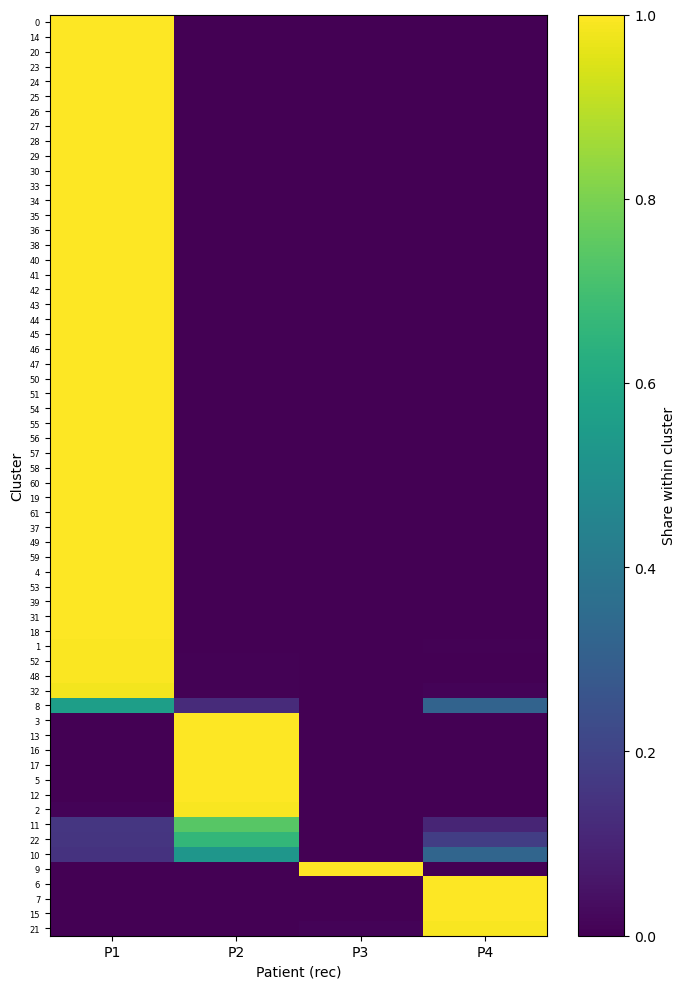

In [19]:
# 每群各病人的比例
patient_id = ids[:, 0].astype(str)

counts = pd.crosstab(lab_fit, patient_id)
counts.index.name = "cluster"
counts.columns.name = "patient"
counts = counts[sorted(counts.columns, key=int)]

ratio = counts.div(counts.sum(axis=1), axis=0)

table = (ratio * 100).round(2)
table.insert(0, "n", counts.sum(axis=1))
table["top_patient"] = ratio.idxmax(axis=1)
table["top_share"] = (ratio.max(axis=1) * 100).round(2)
table = table.rename(index={-1: "noise"})

table.to_csv("cluster_patient_ratio.csv", encoding="utf-8-sig")

# 全部印出來
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 200):
    display(table)

# 熱圖：主要病人一樣的群排在一起，再照占比排
clusters_only = ratio.drop(index=-1, errors="ignore")
order = (
    clusters_only.assign(
        top_patient=clusters_only.idxmax(axis=1),
        top_share=clusters_only.max(axis=1),
    )
    .sort_values(["top_patient", "top_share"], ascending=[True, False])
    .index
)

plot_data = clusters_only.loc[order]
fig, ax = plt.subplots(figsize=(7, max(10, len(plot_data) * 0.16)))
im = ax.imshow(plot_data.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(plot_data.shape[1]))
ax.set_xticklabels([f"P{p}" for p in plot_data.columns])
ax.set_yticks(range(plot_data.shape[0]))
ax.set_yticklabels(plot_data.index, fontsize=6)
ax.set_xlabel("Patient (rec)")
ax.set_ylabel("Cluster")
fig.colorbar(im, ax=ax, label="Share within cluster")
plt.tight_layout()

In [ ]:
# # HDBSCAN 分群
# MIN_CLUSTER_SIZE = 50    
# MIN_SAMPLES      = None     

# hdb = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
# lab_fit = hdb.fit_predict(E_fit)                       # 群號，-1 = 雜訊
# n_clu = lab_fit.max() + 1

# print(f"群數 = {n_clu}，雜訊 = {(lab_fit < 0).sum()} 口（{(lab_fit < 0).mean():.2%}）")
# print(pd.Series(lab_fit, name="口數").value_counts().sort_index().to_string())